# 03. 신경망: 활성화 함수, `nn.Module`, 분류

선형층(`nn.Linear`) 사이에 **비선형 활성화 함수**를 끼우면 곡선 형태의 경계도 학습할 수 있다.
이것이 다층 퍼셉트론(MLP)이다.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs

torch.manual_seed(0)

## 1. 활성화 함수

| 함수 | 출력 범위 | 주 사용처 |
| --- | --- | --- |
| ReLU | $[0, \infty)$ | 은닉층 기본값 |
| Sigmoid | $(0, 1)$ | 이진 분류 출력 (확률) |
| Tanh | $(-1, 1)$ | RNN 은닉 상태 |
| GELU | ReLU를 부드럽게 만든 형태 | Transformer / GPT |

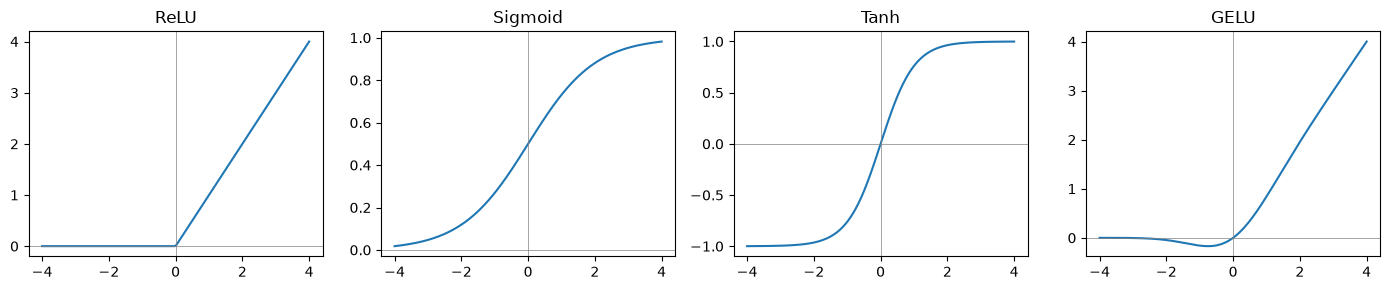

In [2]:
z = torch.linspace(-4, 4, 200)
acts = {"ReLU": torch.relu, "Sigmoid": torch.sigmoid, "Tanh": torch.tanh, "GELU": nn.GELU()}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, fn) in zip(axes, acts.items()):
    ax.plot(z, fn(z))
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 2. 왜 비선형이 필요한가 — XOR

선형층만 여러 개 쌓으면 $W_2(W_1x) = (W_2W_1)x$ 라서 결국 선형층 하나와 같다. XOR은 직선 하나로 나눌 수 없다.

In [3]:
X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
Y = torch.tensor([[0.], [1.], [1.], [0.]])

def fit(model, steps=2000):
    opt = torch.optim.Adam(model.parameters(), lr=0.05)
    loss_fn = nn.BCEWithLogitsLoss()
    for _ in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(X), Y)
        loss.backward()
        opt.step()
    return loss.item()

torch.manual_seed(0)
linear_only = nn.Sequential(nn.Linear(2, 8), nn.Linear(8, 1))
mlp = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
for name, m in [("Linear만", linear_only), ("Linear+ReLU", mlp)]:
    loss = fit(m)
    with torch.no_grad():
        pred = (m(X) > 0).int().squeeze().tolist()
    print(f"{name:12s} loss={loss:.3f}  예측={pred}  정답=[0, 1, 1, 0]")

Linear만      loss=0.693  예측=[0, 0, 0, 0]  정답=[0, 1, 1, 0]


Linear+ReLU  loss=0.000  예측=[0, 1, 1, 0]  정답=[0, 1, 1, 0]


## 3. `nn.Module`로 모델 정의하기

- `__init__`: 레이어를 **속성으로** 등록하면 그 파라미터가 자동으로 추적된다 (`model.parameters()`).
- `forward`: 계산 흐름. `model(x)`를 호출하면 실행된다.
- 출력은 보통 **logits**(sigmoid/softmax를 적용하기 전 값)로 둔다. 손실 함수가 내부에서 처리한다.

In [4]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.out = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.out(x)          # logits


model = MLP(2, 32, 1)
print(model)
print("파라미터 수:", sum(p.numel() for p in model.parameters()))   # (2*32+32) + (32*32+32) + (32+1)

MLP(
  (fc1): Linear(in_features=2, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=32, bias=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)
파라미터 수: 1185


## 4. 이진 분류 — 반달(moons) 데이터

- 출력 1개 (logit)
- 손실 `nn.BCEWithLogitsLoss` = Sigmoid + Binary Cross-Entropy (합쳐 놓은 쪽이 수치적으로 안정적)
- 라벨은 `float`, 모양은 출력과 같은 `(N, 1)`
- 예측: `logit > 0` ⇔ `sigmoid(logit) > 0.5`

In [5]:
Xn, yn = make_moons(n_samples=1000, noise=0.2, random_state=0)
X = torch.tensor(Xn, dtype=torch.float32)
y = torch.tensor(yn, dtype=torch.float32).unsqueeze(1)          # (1000, 1)
X_train, y_train, X_test, y_test = X[:800], y[:800], X[800:], y[800:]

torch.manual_seed(0)
model = MLP(2, 32, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X_train), y_train)
    loss.backward()
    optimizer.step()

    if epoch % 50 == 0 or epoch == 299:
        model.eval()
        with torch.no_grad():
            acc = ((model(X_test) > 0).float() == y_test).float().mean()
        print(f"epoch {epoch:3d}  train loss {loss.item():.4f}  test acc {acc:.3f}")

epoch   0  train loss 0.7145  test acc 0.505


epoch  50  train loss 0.1218  test acc 0.940


epoch 100  train loss 0.0777  test acc 0.965


epoch 150  train loss 0.0715  test acc 0.960


epoch 200  train loss 0.0688  test acc 0.960


epoch 250  train loss 0.0667  test acc 0.960


epoch 299  train loss 0.0650  test acc 0.960


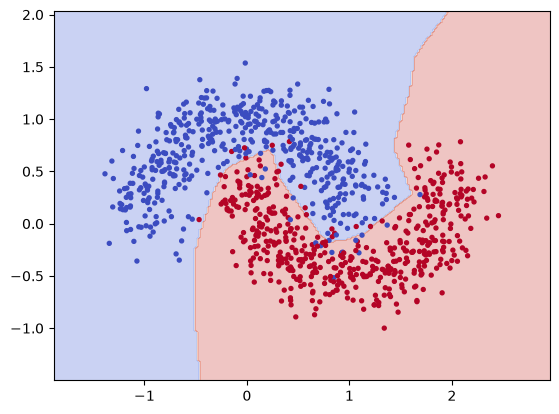

In [6]:
def plot_boundary(model, X, y):
    xx, yy = torch.meshgrid(torch.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                            torch.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    with torch.no_grad():
        out = model(grid)
        zz = (out > 0).float() if out.shape[1] == 1 else out.argmax(dim=1).float()
    plt.contourf(xx, yy, zz.view(xx.shape), alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), s=8, cmap="coolwarm")
    plt.show()

plot_boundary(model, X, y)

## 5. 다중 분류 — 클래스 3개

- 출력 = 클래스 수만큼의 logits `(N, 3)`
- 손실 `nn.CrossEntropyLoss` = Softmax + 음의 로그우도 (**Softmax를 모델에 넣지 않는다**)
- 라벨은 one-hot이 아니라 **클래스 번호 `long`**, 모양 `(N,)`
- 확률이 필요하면 `torch.softmax(logits, dim=1)`, 예측은 `argmax(dim=1)`

loss 0.4425, acc 0.798
처음 3개 샘플 확률:
 tensor([[0.4420, 0.0000, 0.5580],
        [0.7060, 0.2230, 0.0720],
        [0.8080, 0.0270, 0.1650]]) 
정답: [0, 0, 0]


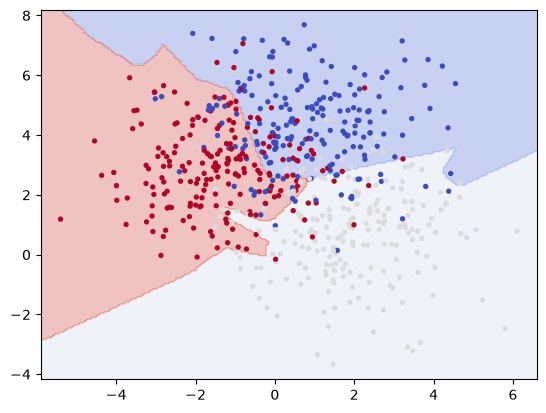

In [7]:
Xn, yn = make_blobs(n_samples=600, centers=3, cluster_std=1.5, random_state=0)
X = torch.tensor(Xn, dtype=torch.float32)
y = torch.tensor(yn, dtype=torch.long)                  # (600,)

torch.manual_seed(0)
model = MLP(2, 32, 3)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(200):
    optimizer.zero_grad()
    logits = model(X)                                   # (600, 3)
    loss = loss_fn(logits, y)
    loss.backward()
    optimizer.step()

with torch.no_grad():
    logits = model(X)
    acc = (logits.argmax(dim=1) == y).float().mean()
    print(f"loss {loss.item():.4f}, acc {acc:.3f}")
    print("처음 3개 샘플 확률:\n", torch.softmax(logits[:3], dim=1).round(decimals=3), "\n정답:", y[:3].tolist())

plot_boundary(model, X, y)

## 6. `model.train()` / `model.eval()`

Dropout(무작위로 일부를 0으로 만드는 정규화) 같은 레이어는 모드에 따라 다르게 동작한다.
학습 중에는 남은 값을 `1/(1-p)`배 키워서 기댓값을 맞추고, 평가 모드에서는 아무것도 하지 않는다.

In [8]:
drop = nn.Dropout(p=0.5)
x = torch.ones(8)
drop.train()
print("train:", drop(x))
drop.eval()
print("eval :", drop(x))

train: tensor([0., 2., 0., 2., 2., 2., 2., 0.])
eval : tensor([1., 1., 1., 1., 1., 1., 1., 1.])
